In [1]:
# General
import os
from pathlib import Path

# data manipulation
import json
import pandas as pd
# import numpy as np

# Visualization
import seaborn as sns
import matplotlib.pyplot as plt
# from matplotlib import cm

# Interactive Jupyter
from IPython.display import display

# others
import contractions
from scipy.stats import pearsonr, ttest_ind 
import nltk
nltk.download('stopwords')

import structural_analysis as ut



[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\mered\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [2]:
# PATH PROJECT SETUP
PROJECT_ROOT = Path.cwd().parent.parent
FIGURES_DIR = PROJECT_ROOT / 'figures'

# DATA DIRECTORIES
DATA_DIR = PROJECT_ROOT / 'data' / 'newyorker_caption_contest'
JSON_DIR = DATA_DIR / 'contests.json'
CSV_DIR = DATA_DIR / 'data'
CSV_CLEAN_DIR = DATA_DIR / 'data_cleaned'
IMG_DIR = DATA_DIR / 'images'

print("Project path setup:")
print("PROJECT_ROOT:  ", PROJECT_ROOT)
print("FIGURES_DIR:   ", FIGURES_DIR)
print("\nDATA_DIR:      ", DATA_DIR)
print("JSON_DIR:      ", JSON_DIR)
print("CSV_DIR:       ", CSV_DIR)
print("CSV_CLEAN_DIR: ", CSV_CLEAN_DIR)
print("IMG_DIR:       ", IMG_DIR)

Project path setup:
PROJECT_ROOT:   c:\Users\mered\OneDrive\Escritorio\Marina\MA2\ADA\ada-2025-project-json-derulo
FIGURES_DIR:    c:\Users\mered\OneDrive\Escritorio\Marina\MA2\ADA\ada-2025-project-json-derulo\figures

DATA_DIR:       c:\Users\mered\OneDrive\Escritorio\Marina\MA2\ADA\ada-2025-project-json-derulo\data\newyorker_caption_contest
JSON_DIR:       c:\Users\mered\OneDrive\Escritorio\Marina\MA2\ADA\ada-2025-project-json-derulo\data\newyorker_caption_contest\contests.json
CSV_DIR:        c:\Users\mered\OneDrive\Escritorio\Marina\MA2\ADA\ada-2025-project-json-derulo\data\newyorker_caption_contest\data
CSV_CLEAN_DIR:  c:\Users\mered\OneDrive\Escritorio\Marina\MA2\ADA\ada-2025-project-json-derulo\data\newyorker_caption_contest\data_cleaned
IMG_DIR:        c:\Users\mered\OneDrive\Escritorio\Marina\MA2\ADA\ada-2025-project-json-derulo\data\newyorker_caption_contest\images


### Data handling, cleaning up for structural analysis

In [3]:
base_path = r"C:\Users\mered\OneDrive\Escritorio\Marina\MA2\ADA\ada-2025-project-json-derulo\data\newyorker_caption_contest\newyorker_caption_contest\data_cleaned"

df = ut.load_all_contest_data(base_path, start_id=510, end_id= 895)

# Check column names first
print("Columns in df:", df.columns.tolist())

# Look for caption column - it might have a different name
# Common possibilities: 'caption', 'Caption', 'text', 'Text', 'joke', 'response'
for col in df.columns:
    if 'caption' in col.lower() or 'text' in col.lower() or 'joke' in col.lower():
        print(f"Found possible caption column: '{col}'")
        print(f"Missing values in '{col}': {df[col].isna().sum()}")

Missing files for contest IDs: [525, 540]
Successfully loaded 384 files
Total rows: 2263105
Columns in df: ['rank', 'caption', 'mean', 'precision', 'votes', 'not_funny', 'somewhat_funny', 'funny', 'contest_id']
Found possible caption column: 'caption'
Missing values in 'caption': 50


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2263105 entries, 0 to 2263104
Data columns (total 9 columns):
 #   Column          Dtype  
---  ------          -----  
 0   rank            int64  
 1   caption         object 
 2   mean            float64
 3   precision       float64
 4   votes           int64  
 5   not_funny       int64  
 6   somewhat_funny  int64  
 7   funny           int64  
 8   contest_id      int64  
dtypes: float64(2), int64(6), object(1)
memory usage: 155.4+ MB


Make the captions more fluid by: 
- erasing unnecessary punctuations 
- lowercase all the captions 
- handling contractions to normalise all the captions 
        -> necessary for comparison 

In [5]:
print("Columns in the DataFrame:")
print(df.columns.tolist())

# check for missing values and fill NaN w/ empty string or remove them
print(f"missing values in caption: {df['caption'].isna().sum()}")
df["caption"] = df["caption"].fillna("")

# erase unnecessary punctuations :
df["caption"] = df["caption"].str.replace(r"[--]", " ", regex=True)
df["caption"] = df["caption"].str.replace(r"[.,?]", " ", regex=True)

# lowercase : 
df["caption"] = df["caption"].str.lower()

# contractions :
df["caption"] = df["caption"].apply(lambda x: contractions.fix(x))   

print(df["caption"].head()) # check

Columns in the DataFrame:
['rank', 'caption', 'mean', 'precision', 'votes', 'not_funny', 'somewhat_funny', 'funny', 'contest_id']
missing values in caption: 50
0           i am a congressman  obstruction is my job 
1    i am what they mean when they say  'the middle...
2                    does this suit make me look flat 
3    when the right woman comes along  i will know it 
4    i used to lie in the gutter  but then i quit d...
Name: caption, dtype: object


Are longer jokes funnier than short ones: 

In [6]:
# words
df["word_counts"] = [len(line.split()) for line in df["caption"]]

# characters 
df["length"] = [len(line) for line in df["caption"]]

# average of words and characters
print(f"avg word count: {df['word_counts'].mean():.2f}")
print(f"avg character count: {df['length'].mean():.2f}")
print(f"data set size: {len(df)} captions")

avg word count: 10.56
avg character count: 53.43
data set size: 2263105 captions



correlation w/ funny Score:
# of words correlation: -0.038 (p-value: 0.000)
# of characters correlation: -0.043 (p-value: 0.000)


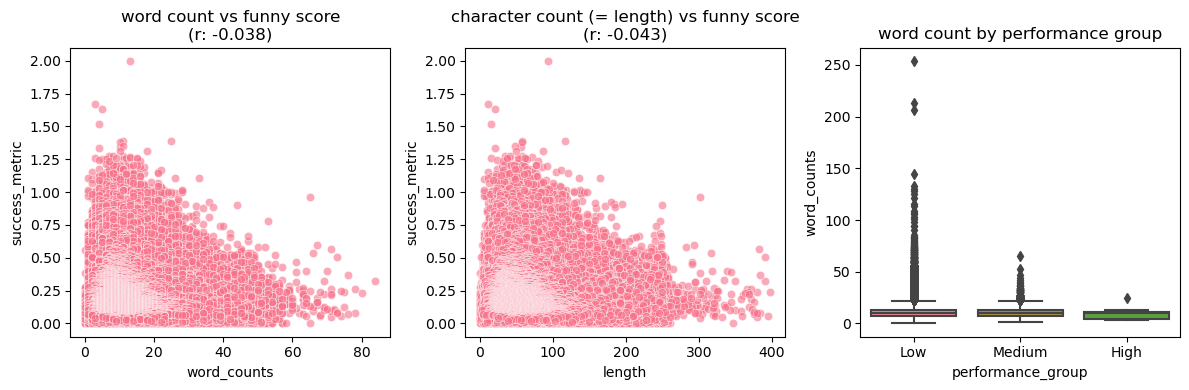

In [9]:
# style of plot
plt.style.use('default')
sns.set_palette("husl")

# scores
df['total_votes'] = df['not_funny'] + df['somewhat_funny'] + df['funny'] # this is for each caption 

# proportions for each category
df['prop_not_funny'] = df['not_funny'] / df['total_votes']
df['prop_somewhat_funny'] = df['somewhat_funny'] / df['total_votes']
df['prop_funny'] = df['funny'] / df['total_votes']

# weighted average (2 for funny, 1 for somewhat_funny, 0 for not_funny)
df['funny_score_weighted'] = (df['funny'] * 2 + df['somewhat_funny'] * 1 + df['not_funny'] * 0) / df['total_votes']
df['success_metric'] = df['funny_score_weighted']

# correlation analysis 
corr_word_score, p_word = pearsonr(df['word_counts'], df['success_metric'])
corr_char_score, p_char = pearsonr(df['length'], df['success_metric'])

print(f"\ncorrelation w/ funny Score:")
print(f"# of words correlation: {corr_word_score:.3f} (p-value: {p_word:.3f})")
print(f"# of characters correlation: {corr_char_score:.3f} (p-value: {p_char:.3f})")

df_filtered = df[(df['word_counts'] <= 100) & (df['length'] <= 400)]

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
sns.scatterplot(data=df_filtered, x='word_counts', y='success_metric', alpha=0.6)
plt.title(f'word count vs funny score\n(r: {corr_word_score:.3f})')

plt.subplot(1, 3, 2)
sns.scatterplot(data=df_filtered, x='length', y='success_metric', alpha=0.6)
plt.title(f'character count (= length) vs funny score\n(r: {corr_char_score:.3f})')

plt.subplot(1, 3, 3)
# Create performance groups for comparison
df['performance_group'] = pd.cut(df['success_metric'], bins=3, labels=['Low', 'Medium', 'High'])

sns.boxplot(data=df, x='performance_group', y='word_counts')
plt.title('word count by performance group')

plt.tight_layout()
plt.show()



In [9]:
# statistical test for performance comparison & word count performance 

top_cutoff = df['success_metric'].quantile(0.8)
bottom_cutoff = df['success_metric'].quantile(0.2)

top_captions = df[df['success_metric'] >= top_cutoff]
bottom_captions = df[df['success_metric'] <= bottom_cutoff]

print(f"\nperformance comparison:")
print(f"top 20% cutoff: {top_cutoff:.3f} ({len(top_captions)} captions)")
print(f"bottom 20% cutoff: {bottom_cutoff:.3f} ({len(bottom_captions)} captions)")

# Compare metrics
print(f"\nword count comparison:")
print(f"top performers: {top_captions['word_counts'].mean():.1f} ± {top_captions['word_counts'].std():.1f}")
print(f"bottom performers: {bottom_captions['word_counts'].mean():.1f} ± {bottom_captions['word_counts'].std():.1f}")

print(f"\nlength count comparison:")
print(f"top performers: {top_captions['length'].mean():.1f} ± {top_captions['length'].std():.1f}")
print(f"bottom performers: {bottom_captions['length'].mean():.1f} ± {bottom_captions['length'].std():.1f}")

# Statistical test
t_stat, p_val = ttest_ind(top_captions['word_counts'], bottom_captions['word_counts'])
print(f"t-test p-value words: {p_val:.4f}")

t_stat, p_val = ttest_ind(top_captions['length'], bottom_captions['length'])
print(f"t-test p-value characters: {p_val:.4f}")




performance comparison:
top 20% cutoff: 0.298 (453068 captions)
bottom 20% cutoff: 0.118 (456797 captions)

word count comparison:
top performers: 10.3 ± 4.6
bottom performers: 10.9 ± 5.7

length count comparison:
top performers: 51.9 ± 23.3
bottom performers: 55.5 ± 29.1
t-test p-value words: 0.0000
t-test p-value characters: 0.0000


Speerman's rank correlation 

- Why? it assumes linear relationships and is sensitive to outliers 
 => it looks at monotonic relationships 
- what it adds? it suggests outliers or non-linear patterns 
=> in jokes maybe there’s a threshold effect (jokes need min/max length)


In [10]:
from scipy.stats import spearmanr

# the correlation calculation: 
spearman_word, p_spearman_word = spearmanr(df['word_counts'], df['success_metric'])
spearman_character, p_spearman_character = spearmanr(df['length'], df['success_metric'])

print(f"\nSpearman words correlation: {spearman_word} (p-value : {p_spearman_word:.4f})")
print(f"\nSpearman characters correlation: {spearman_character} (p-value : {p_spearman_character:.4f})")

# compare with pearson correlation 
print(f"\nPearson: {corr_word_score:.3f}, Spearman: {spearman_word:.3f}")
print(f"\nPearson: {corr_char_score:.3f}, Spearman: {spearman_character:.3f}")

# Interpretation
if abs(spearman_word - corr_word_score) > 0.1: 
    print("significant difference btw Pearson and Spearman: suggests non-linear relationship or outliers")
else: 
    print("Similar Pearson and Spearman values suggest linear relationship")


Spearman words correlation: -0.026460799371431906 (p-value : 0.0000)

Spearman characters correlation: -0.031078503717199262 (p-value : 0.0000)

Pearson: -0.038, Spearman: -0.026

Pearson: -0.043, Spearman: -0.031
Similar Pearson and Spearman values suggest linear relationship


Partial correlation: (controlling for potential confounders)
- why? controls for confounding variables (maybe certain joke categories genre puns/stories) are both long AND funnier 
- what it adds? a more purified relationship between length & funniness 
=> if drops to near 0, length might not matter 


In [11]:
import statsmodels.api as sm 
def partial_correlation_manual(df, x, y, control_variables): 
    x_control = sm.add_constant(df[control_variables])
    model_x = sm.OLS(df[x], x_control).fit()
    res_x = model_x.resid
    model_y = sm.OLS(df[y], x_control).fit()
    res_y = model_y.resid

    partial_corr, p_value = pearsonr(res_x, res_y)
    return partial_corr, p_value, res_x, res_y

## control for # of votes (sample size effect)
partial_corr_votes, p_partial_corr_votes, _, _ =  partial_correlation_manual(df, 'word_counts', 'success_metric', ['votes'])
print(f"Partial corr: {partial_corr_votes:.3f} vs simple corr: {corr_word_score:.3f}")
print(f"p-value: {p_partial_corr_votes:.4f}")


Partial corr: -0.039 vs simple corr: -0.038
p-value: 0.0000


LOESS



NON-LINEAR RELATIONSHIP ANALYSIS

Linear model R²: 0.0015
Polynomial (quadratic) model R²: 0.0019

Polynomial coefficients:
  Linear term (word_counts): -0.0000
  Quadratic term (word_counts²): -0.0000

Statistical significance (OLS):
  Quadratic term p-value: 0.0000

LOESS analysis suggests optimal joke length: 9.0 words


c:\Users\mered\anaconda3\Lib\site-packages\sklearn\base.py:464: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(


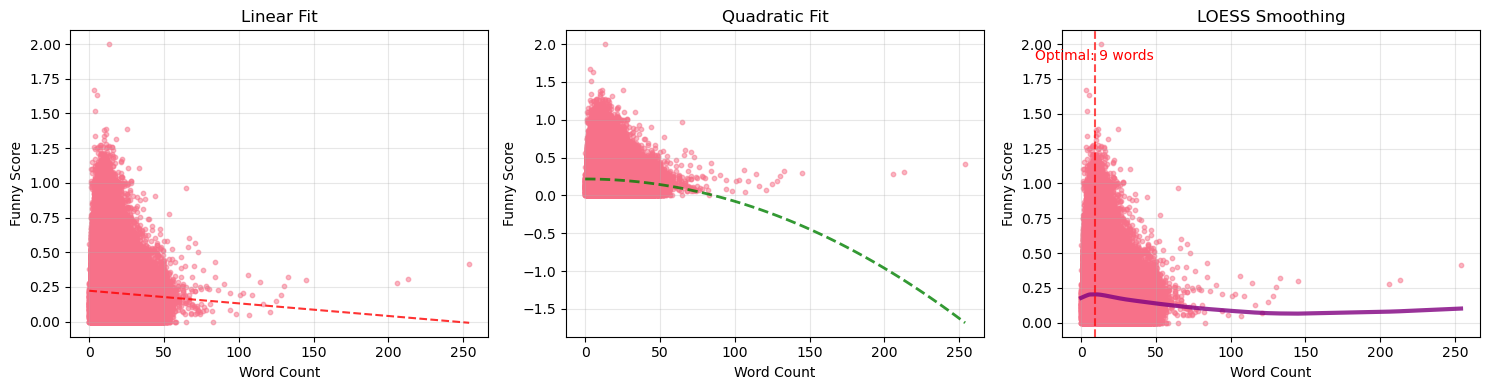

In [30]:
import numpy as np
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
import statsmodels.api as sm

print("\n" + "=" * 60)
print("NON-LINEAR RELATIONSHIP ANALYSIS")
print("=" * 60)

# Polynomial regression (degree 2)
poly = PolynomialFeatures(degree=2, include_bias=False)
X_poly = poly.fit_transform(df[['word_counts']])
poly_feature_names = ['word_counts', 'word_counts^2']

model_poly = LinearRegression()
model_poly.fit(X_poly, df['success_metric'])

# Get R-squared for comparison
X_linear = df[['word_counts']]
model_linear = LinearRegression()
model_linear.fit(X_linear, df['success_metric'])

print(f"\nLinear model R²: {model_linear.score(X_linear, df['success_metric']):.4f}")
print(f"Polynomial (quadratic) model R²: {model_poly.score(X_poly, df['success_metric']):.4f}")
print(f"\nPolynomial coefficients:")
print(f"  Linear term (word_counts): {model_poly.coef_[0]:.4f}")
print(f"  Quadratic term (word_counts²): {model_poly.coef_[1]:.4f}")

# Statistical significance of quadratic term using statsmodels
X_poly_sm = sm.add_constant(X_poly)
model_poly_sm = sm.OLS(df['success_metric'], X_poly_sm).fit()
print(f"\nStatistical significance (OLS):")
print(f"  Quadratic term p-value: {model_poly_sm.pvalues[2]:.4f}")

# LOESS smoothing
lowess = sm.nonparametric.lowess(df['success_metric'], df['word_counts'], 
                                  frac=0.3, it=3)

# Find optimal length (maximum of LOESS curve)
optimal_idx = np.argmax(lowess[:, 1])
optimal_length = lowess[optimal_idx, 0]

print(f"\nLOESS analysis suggests optimal joke length: {optimal_length:.1f} words")

# Plotting
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Scatter with linear fit
axes[0].scatter(df['word_counts'], df['success_metric'], alpha=0.5, s=10)
z = np.polyfit(df['word_counts'], df['success_metric'], 1)
p = np.poly1d(z)
x_range = np.linspace(df['word_counts'].min(), df['word_counts'].max(), 100)
axes[0].plot(x_range, p(x_range), "r--", alpha=0.8)
axes[0].set_xlabel('Word Count')
axes[0].set_ylabel('Funny Score')
axes[0].set_title('Linear Fit')
axes[0].grid(True, alpha=0.3)

# Scatter with quadratic fit
axes[1].scatter(df['word_counts'], df['success_metric'], alpha=0.5, s=10)
# Generate predictions from quadratic model
x_quad = np.linspace(df['word_counts'].min(), df['word_counts'].max(), 100)
x_quad_poly = poly.transform(x_quad.reshape(-1, 1))
y_quad_pred = model_poly.predict(x_quad_poly)
axes[1].plot(x_quad, y_quad_pred, "g--", alpha=0.8, linewidth=2)
axes[1].set_xlabel('Word Count')
axes[1].set_ylabel('Funny Score')
axes[1].set_title('Quadratic Fit')
axes[1].grid(True, alpha=0.3)

# LOESS plot
axes[2].scatter(df['word_counts'], df['success_metric'], alpha=0.5, s=10)
axes[2].plot(lowess[:, 0], lowess[:, 1], "purple", linewidth=3, alpha=0.8)
axes[2].axvline(x=optimal_length, color='red', linestyle='--', alpha=0.7)
axes[2].text(optimal_length, axes[2].get_ylim()[1]*0.9, 
             f'Optimal: {optimal_length:.0f} words', 
             ha='center', color='red')
axes[2].set_xlabel('Word Count')
axes[2].set_ylabel('Funny Score')
axes[2].set_title('LOESS Smoothing')
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Multivariate regression:

In [31]:
import statsmodels.formula.api as smf

print("\n" + "=" * 60)
print("MULTIVARIATE REGRESSION ANALYSIS")
print("=" * 60)

# Multiple regression including both predictors
model_multi = smf.ols('success_metric ~ word_counts + length', data=df).fit()

print("\n1. Multiple Regression (both predictors):")
print(model_multi.summary().tables[1])

# Check for multicollinearity (VIF)
from statsmodels.stats.outliers_influence import variance_inflation_factor
X_multi = df[['word_counts', 'length']]
vif_data = pd.DataFrame()
vif_data["Variable"] = X_multi.columns
vif_data["VIF"] = [variance_inflation_factor(X_multi.values, i) 
                    for i in range(X_multi.shape[1])]
print("\n2. Variance Inflation Factor (VIF):")
print(vif_data)
print("\nNote: VIF > 5-10 indicates high multicollinearity")

# Interaction model
model_interaction = smf.ols('success_metric ~ word_counts * length', data=df).fit()

print("\n3. Interaction Model:")
print(model_interaction.summary().tables[1])

# Compare models
print("\n4. Model Comparison:")
print(f"Multiple regression R²: {model_multi.rsquared:.4f}")
print(f"Interaction model R²: {model_interaction.rsquared:.4f}")

# Test if interaction is significant
print(f"\n5. Interaction term significance:")
interaction_p = model_interaction.pvalues['word_counts:length']
print(f"Interaction p-value: {interaction_p:.4f}")
if interaction_p < 0.05:
    print("• Significant interaction: Effect of word count depends on character length")
else:
    print("• No significant interaction")


MULTIVARIATE REGRESSION ANALYSIS

1. Multiple Regression (both predictors):
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept       0.2233      0.000   1198.288      0.000       0.223       0.224
word_counts     0.0012   5.93e-05     20.481      0.000       0.001       0.001
length         -0.0004   1.16e-05    -37.166      0.000      -0.000      -0.000

2. Variance Inflation Factor (VIF):
      Variable        VIF
0  word_counts  71.321566
1       length  71.321566

Note: VIF > 5-10 indicates high multicollinearity

3. Interaction Model:
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept              0.2186      0.000    856.370      0.000       0.218       0.219
word_counts            0.0015   6.03e-05     25.051      0.000       0.00

In [32]:
from scipy.stats import f_oneway
from statsmodels.stats.multicomp import pairwise_tukeyhsd

print("\n" + "=" * 60)
print("BINNING ANALYSIS WITH ANOVA")
print("=" * 60)

# Create 10 equal-sized bins based on word count
df['word_bins'] = pd.qcut(df['word_counts'], q=10, labels=range(1, 11))

# Calculate statistics for each bin
bin_stats = df.groupby('word_bins').agg({
    'word_counts': ['min', 'max', 'mean'],
    'success_metric': ['mean', 'std', 'count']
}).round(2)

print("\n1. Statistics by Word Count Bin (deciles):")
print(bin_stats)

# One-way ANOVA
groups = [group['success_metric'].values for _, group in df.groupby('word_bins')]
anova_result = f_oneway(*groups)

print(f"\n2. One-way ANOVA Results:")
print(f"F-statistic: {anova_result.statistic:.2f}")
print(f"p-value: {anova_result.pvalue:.4f}")

if anova_result.pvalue < 0.05:
    print("• Significant differences exist between bins")
    
    # Post-hoc Tukey test
    tukey = pairwise_tukeyhsd(df['success_metric'], df['word_bins'].astype(str), alpha=0.05)
    print("\n3. Tukey HSD Post-hoc Test:")
    print(tukey.summary())
    
    # Find which bins differ
    significant_pairs = []
    for i in range(len(tukey.groupsunique)):
        for j in range(i+1, len(tukey.groupsunique)):
            idx = i * len(tukey.groupsunique) + j
            if tukey.reject[idx]:
                significant_pairs.append((tukey.groupsunique[i], tukey.groupsunique[j]))
    
    if significant_pairs:
        print(f"\n4. Significant bin differences: {len(significant_pairs)} pairs")
        for pair in significant_pairs[:5]:  # Show first 5
            print(f"   Bin {pair[0]} vs Bin {pair[1]}")
else:
    print("• No significant differences between bins")

# Plotting
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Boxplot by bin
sns.boxplot(data=df, x='word_bins', y='success_metric', ax=axes[0])
axes[0].set_xlabel('Word Count Bin (1=shortest, 10=longest)')
axes[0].set_ylabel('Funny Score')
axes[0].set_title('Funny Score Distribution by Word Count Bin')
axes[0].tick_params(axis='x', rotation=45)

# Mean with confidence intervals
bin_means = df.groupby('word_bins')['success_metric'].agg(['mean', 'sem', 'count'])
bin_means['ci'] = 1.96 * bin_means['sem']  # 95% CI

axes[1].errorbar(x=range(1, 11), y=bin_means['mean'], 
                 yerr=bin_means['ci'], fmt='o-', capsize=5)
axes[1].set_xlabel('Word Count Bin')
axes[1].set_ylabel('Mean Funny Score (±95% CI)')
axes[1].set_title('Mean Performance with Confidence Intervals')
axes[1].grid(True, alpha=0.3)

# Highlight optimal bin
optimal_bin = bin_means['mean'].idxmax()
axes[1].axvline(x=optimal_bin, color='red', linestyle='--', alpha=0.5)
axes[1].text(optimal_bin, axes[1].get_ylim()[1]*0.95, 
             f'Optimal: Bin {optimal_bin}', 
             ha='center', color='red')

plt.tight_layout()
plt.show()


BINNING ANALYSIS WITH ANOVA

1. Statistics by Word Count Bin (deciles):
          word_counts             success_metric              
                  min  max   mean           mean   std   count
word_bins                                                     
1                   0    5   4.12           0.21  0.12  259815
2                   6    7   6.55           0.22  0.12  382135
3                   8    8   8.00           0.22  0.12  227413
4                   9    9   9.00           0.22  0.12  225649
5                  10   10  10.00           0.22  0.12  208495
6                  11   11  11.00           0.22  0.13  182779
7                  12   12  12.00           0.22  0.13  155193
8                  13   14  13.45           0.21  0.12  231457
9                  15   17  15.84           0.21  0.12  199203
10                 18  254  22.31           0.19  0.11  190966

2. One-way ANOVA Results:
F-statistic: 696.48
p-value: 0.0000
• Significant differences exist between bins


IndexError: index 45 is out of bounds for axis 0 with size 45

Bayesian analysis


BAYESIAN ANALYSIS (USING ANALYTICAL/NUMERICAL METHODS)
Using sample of 5000 jokes for analysis...

1. ANALYTICAL BAYESIAN LINEAR REGRESSION
----------------------------------------
Posterior mean for beta (effect size): -0.001421
Posterior variance for beta: 0.000000
Posterior standard deviation: 0.000330

2. GRID APPROXIMATION FOR POSTERIOR
----------------------------------------


c:\Users\mered\anaconda3\Lib\site-packages\numpy\core\fromnumeric.py:86: RuntimeWarning: overflow encountered in reduce
  return ufunc.reduce(obj, axis, dtype, out, **passkwargs)
C:\Users\mered\AppData\Local\Temp\ipykernel_18040\3379562880.py:71: RuntimeWarning: invalid value encountered in divide
  posterior = unnormalized_posterior / np.trapz(unnormalized_posterior, beta_grid)


Posterior mean (grid): nan
95% HDI: [-0.100000, 0.100000]

3. BOOTSTRAP UNCERTAINTY QUANTIFICATION
----------------------------------------
Bootstrap mean beta: -0.001416
Bootstrap standard error: 0.000290
95% Bootstrap CI: [-0.001983, -0.000853]

Probability statements (bootstrap):
• Probability that longer jokes are funnier (beta > 0): 0.00%
• Probability that shorter jokes are funnier (beta < 0): 100.00%
• Probability of meaningful effect (>0.001): 0.00%

4. BAYES FACTOR ANALYSIS
----------------------------------------
BIC (null model): -20914.02
BIC (linear model): -20924.03
Bayes Factor (linear vs null): 149.53
Interpretation: Decisive evidence for effect

5. VISUALIZING RESULTS
----------------------------------------


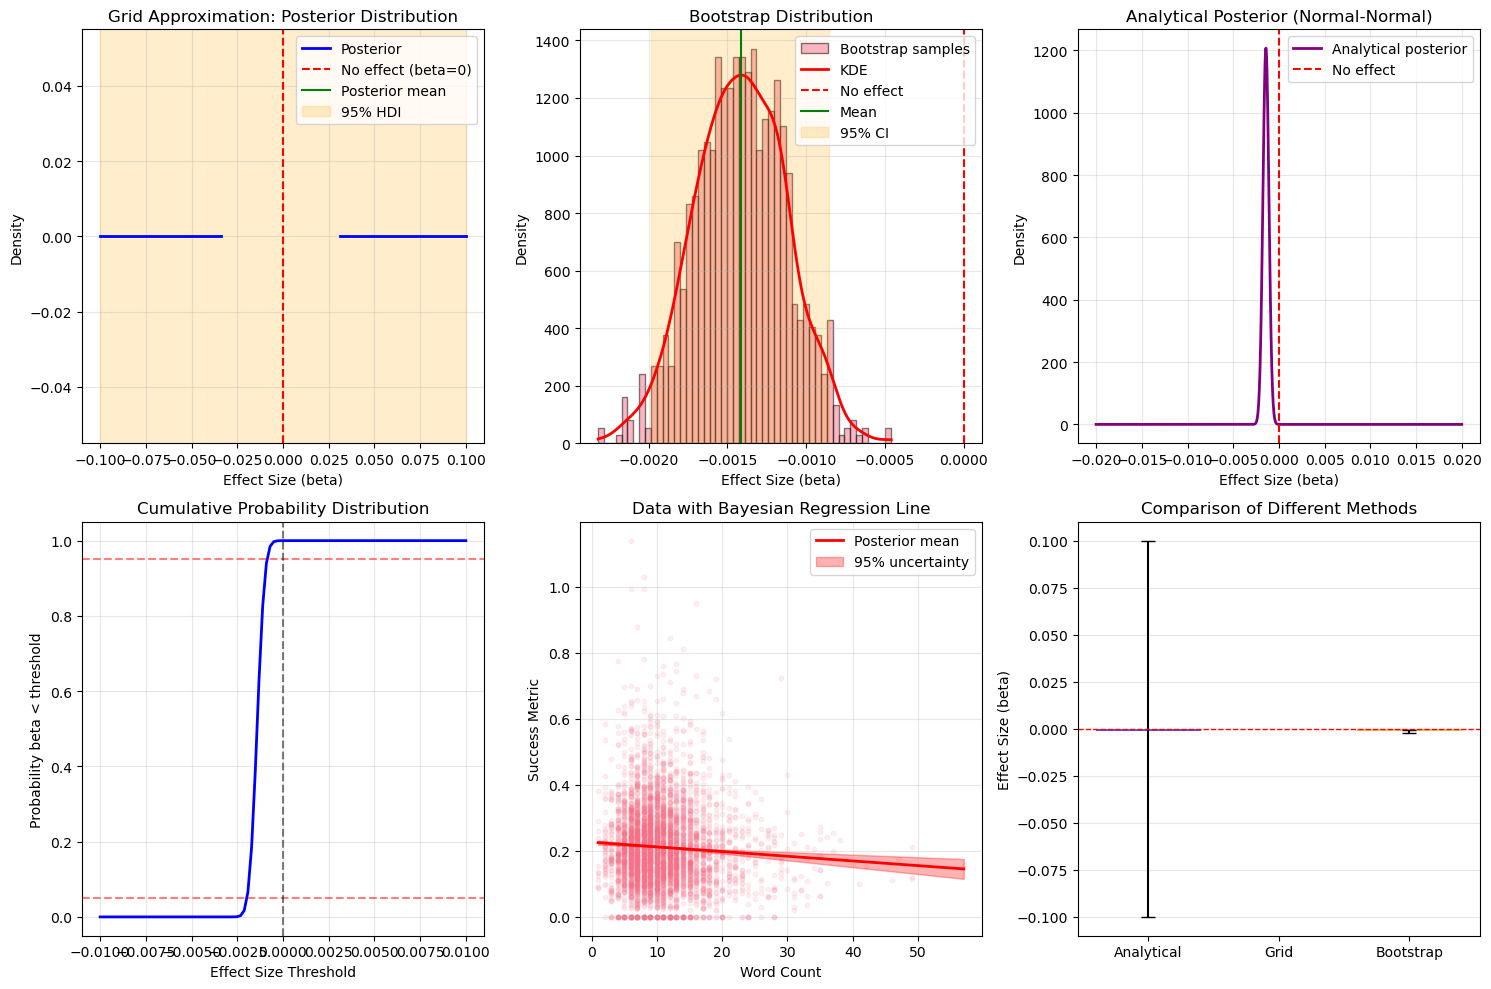


SUMMARY AND INTERPRETATION

Overall effect of word count on success:
• Average effect size: -0.001421
• 95% uncertainty interval: [-0.001983, -0.000853]
• Probability of positive effect: 0.0%
• Bayes factor (evidence for effect): 149.5

Conclusion: INCONCLUSIVE evidence about joke length effect

Practical interpretation:


NameError: name 'poster_mean_beta' is not defined

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm, gaussian_kde
from scipy.special import erf

print("\n" + "=" * 60)
print("BAYESIAN ANALYSIS (USING ANALYTICAL/NUMERICAL METHODS)")
print("=" * 60)

# Use smaller sample for faster computation
sample_size = min(5000, len(df))  # Can use larger sample since we're not using MCMC
df_sample = df.sample(n=sample_size, random_state=42)
print(f"Using sample of {sample_size} jokes for analysis...")

# ========== METHOD 1: ANALYTICAL BAYESIAN LINEAR REGRESSION ==========
print("\n1. ANALYTICAL BAYESIAN LINEAR REGRESSION")
print("-" * 40)

# Prepare data
X = df_sample['word_counts'].values
y = df_sample['success_metric'].values

# Center the data
X_mean = np.mean(X)
y_mean = np.mean(y)
X_centered = X - X_mean
y_centered = y - y_mean

# Set priors
# Prior precision (inverse of variance)
tau_prior = 1.0  # Prior precision for beta
alpha_prior = 0.0  # Prior mean for beta (centered at no effect)

# Compute posterior parameters analytically
# For normal-normal conjugate prior
n = len(X)
sigma_sq = np.var(y_centered - X_centered * alpha_prior)  # Initial guess

# Posterior for beta (effect size)
posterior_var_beta = 1 / (tau_prior + np.sum(X_centered**2) / sigma_sq)
posterior_mean_beta = posterior_var_beta * (tau_prior * alpha_prior + np.sum(X_centered * y_centered) / sigma_sq)

print(f"Posterior mean for beta (effect size): {posterior_mean_beta:.6f}")
print(f"Posterior variance for beta: {posterior_var_beta:.6f}")
print(f"Posterior standard deviation: {np.sqrt(posterior_var_beta):.6f}")

# ========== METHOD 2: GRID APPROXIMATION ==========
print("\n2. GRID APPROXIMATION FOR POSTERIOR")
print("-" * 40)

# Create grid of possible beta values
beta_grid = np.linspace(-0.1, 0.1, 1000)  # Range of plausible effect sizes

# Prior: normal distribution centered at 0
prior = norm.pdf(beta_grid, loc=0, scale=0.05)

# Likelihood function (assuming normal errors)
def likelihood(beta_val):
    residuals = y - (y_mean + beta_val * X_centered)
    sigma = np.std(residuals)
    return np.prod(norm.pdf(y, loc=y_mean + beta_val * X_centered, scale=sigma))

# Calculate likelihood for each beta value
likelihood_vals = np.array([likelihood(b) for b in beta_grid])

# Calculate unnormalized posterior
unnormalized_posterior = prior * likelihood_vals

# Normalize posterior
posterior = unnormalized_posterior / np.trapz(unnormalized_posterior, beta_grid)

# Find posterior mean and HDI
posterior_mean_grid = np.trapz(beta_grid * posterior, beta_grid)
posterior_cdf = np.cumsum(posterior) * (beta_grid[1] - beta_grid[0])
posterior_cdf /= posterior_cdf[-1]  # Normalize

# Find 95% HDI (Highest Density Interval)
def find_hdi(grid, pdf, alpha=0.05):
    # Sort by density
    sorted_indices = np.argsort(pdf)[::-1]
    cumulative_prob = 0
    hdi_indices = []
    
    for idx in sorted_indices:
        hdi_indices.append(idx)
        cumulative_prob += pdf[idx] * (grid[1] - grid[0])
        if cumulative_prob >= 1 - alpha:
            break
    
    hdi_indices = np.sort(hdi_indices)
    return grid[hdi_indices[0]], grid[hdi_indices[-1]]

hdi_lower, hdi_upper = find_hdi(beta_grid, posterior)

print(f"Posterior mean (grid): {posterior_mean_grid:.6f}")
print(f"95% HDI: [{hdi_lower:.6f}, {hdi_upper:.6f}]")

# ========== METHOD 3: BOOTSTRAP FOR UNCERTAINTY QUANTIFICATION ==========
print("\n3. BOOTSTRAP UNCERTAINTY QUANTIFICATION")
print("-" * 40)

n_bootstrap = 1000
bootstrap_betas = []

for i in range(n_bootstrap):
    # Bootstrap sample
    indices = np.random.choice(len(df_sample), size=len(df_sample), replace=True)
    X_boot = df_sample['word_counts'].values[indices]
    y_boot = df_sample['success_metric'].values[indices]
    
    # Simple linear regression
    X_boot_centered = X_boot - np.mean(X_boot)
    y_boot_centered = y_boot - np.mean(y_boot)
    
    beta_boot = np.sum(X_boot_centered * y_boot_centered) / np.sum(X_boot_centered**2)
    bootstrap_betas.append(beta_boot)

bootstrap_betas = np.array(bootstrap_betas)

# Calculate statistics
bootstrap_mean = np.mean(bootstrap_betas)
bootstrap_std = np.std(bootstrap_betas)
bootstrap_ci = np.percentile(bootstrap_betas, [2.5, 97.5])

print(f"Bootstrap mean beta: {bootstrap_mean:.6f}")
print(f"Bootstrap standard error: {bootstrap_std:.6f}")
print(f"95% Bootstrap CI: [{bootstrap_ci[0]:.6f}, {bootstrap_ci[1]:.6f}]")

# Probability calculations
prob_positive = np.mean(bootstrap_betas > 0)
prob_negative = np.mean(bootstrap_betas < 0)
prob_meaningful = np.mean(bootstrap_betas > 0.001)  # Meaningful effect threshold

print(f"\nProbability statements (bootstrap):")
print(f"• Probability that longer jokes are funnier (beta > 0): {prob_positive:.2%}")
print(f"• Probability that shorter jokes are funnier (beta < 0): {prob_negative:.2%}")
print(f"• Probability of meaningful effect (>0.001): {prob_meaningful:.2%}")

# ========== METHOD 4: BAYES FACTOR CALCULATION ==========
print("\n4. BAYES FACTOR ANALYSIS")
print("-" * 40)

# Bayes factor comparing H1 (beta ≠ 0) vs H0 (beta = 0)
# Using BIC approximation

def calculate_bic(y_true, y_pred, n_params):
    """Calculate Bayesian Information Criterion"""
    n = len(y_true)
    residuals = y_true - y_pred
    rss = np.sum(residuals**2)
    bic = n * np.log(rss / n) + n_params * np.log(n)
    return bic

# Model 0: Null model (intercept only)
y_pred_null = np.full_like(y, np.mean(y))
bic_null = calculate_bic(y, y_pred_null, n_params=1)

# Model 1: Linear model with word count
# Simple OLS estimate
beta_ols = np.sum(X_centered * y_centered) / np.sum(X_centered**2)
y_pred_linear = y_mean + beta_ols * X_centered
bic_linear = calculate_bic(y, y_pred_linear, n_params=2)

# Bayes factor approximation (using BIC difference)
bf = np.exp((bic_null - bic_linear) / 2)

print(f"BIC (null model): {bic_null:.2f}")
print(f"BIC (linear model): {bic_linear:.2f}")
print(f"Bayes Factor (linear vs null): {bf:.2f}")

if bf > 100:
    evidence = "Decisive evidence for effect"
elif bf > 30:
    evidence = "Very strong evidence for effect"
elif bf > 10:
    evidence = "Strong evidence for effect"
elif bf > 3:
    evidence = "Moderate evidence for effect"
elif bf > 1:
    evidence = "Anecdotal evidence for effect"
else:
    evidence = "Evidence favors null hypothesis"

print(f"Interpretation: {evidence}")

# ========== VISUALIZATION ==========
print("\n5. VISUALIZING RESULTS")
print("-" * 40)

fig, axes = plt.subplots(2, 3, figsize=(15, 10))

# 1. Grid approximation posterior
axes[0, 0].plot(beta_grid, posterior, 'b-', linewidth=2, label='Posterior')
axes[0, 0].fill_between(beta_grid, posterior, alpha=0.3, color='blue')
axes[0, 0].axvline(x=0, color='red', linestyle='--', label='No effect (beta=0)')
axes[0, 0].axvline(x=posterior_mean_grid, color='green', linestyle='-', label='Posterior mean')
axes[0, 0].axvspan(hdi_lower, hdi_upper, alpha=0.2, color='orange', label='95% HDI')
axes[0, 0].set_xlabel('Effect Size (beta)')
axes[0, 0].set_ylabel('Density')
axes[0, 0].set_title('Grid Approximation: Posterior Distribution')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# 2. Bootstrap distribution
kde = gaussian_kde(bootstrap_betas)
beta_smooth = np.linspace(bootstrap_betas.min(), bootstrap_betas.max(), 1000)
axes[0, 1].hist(bootstrap_betas, bins=50, density=True, alpha=0.5, edgecolor='black', label='Bootstrap samples')
axes[0, 1].plot(beta_smooth, kde(beta_smooth), 'r-', linewidth=2, label='KDE')
axes[0, 1].axvline(x=0, color='red', linestyle='--', label='No effect')
axes[0, 1].axvline(x=bootstrap_mean, color='green', linestyle='-', label='Mean')
axes[0, 1].axvspan(bootstrap_ci[0], bootstrap_ci[1], alpha=0.2, color='orange', label='95% CI')
axes[0, 1].set_xlabel('Effect Size (beta)')
axes[0, 1].set_ylabel('Density')
axes[0, 1].set_title('Bootstrap Distribution')
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# 3. Probability distribution
beta_range = np.linspace(-0.02, 0.02, 1000)
analytical_posterior = norm.pdf(beta_range, loc=posterior_mean_beta, scale=np.sqrt(posterior_var_beta))
axes[0, 2].plot(beta_range, analytical_posterior, 'purple', linewidth=2, label='Analytical posterior')
axes[0, 2].axvline(x=0, color='red', linestyle='--', label='No effect')
axes[0, 2].set_xlabel('Effect Size (beta)')
axes[0, 2].set_ylabel('Density')
axes[0, 2].set_title('Analytical Posterior (Normal-Normal)')
axes[0, 2].legend()
axes[0, 2].grid(True, alpha=0.3)

# 4. Probability plot
x_prob = np.linspace(-0.01, 0.01, 100)
cdf_vals = norm.cdf(x_prob, loc=posterior_mean_beta, scale=np.sqrt(posterior_var_beta))
axes[1, 0].plot(x_prob, cdf_vals, 'b-', linewidth=2)
axes[1, 0].axhline(y=0.95, color='r', linestyle='--', alpha=0.5)
axes[1, 0].axhline(y=0.05, color='r', linestyle='--', alpha=0.5)
axes[1, 0].axvline(x=0, color='k', linestyle='--', alpha=0.5)
axes[1, 0].set_xlabel('Effect Size Threshold')
axes[1, 0].set_ylabel('Probability beta < threshold')
axes[1, 0].set_title('Cumulative Probability Distribution')
axes[1, 0].grid(True, alpha=0.3)

# 5. Scatter plot with regression line
axes[1, 1].scatter(df_sample['word_counts'], df_sample['success_metric'], alpha=0.1, s=10)
x_plot = np.linspace(df_sample['word_counts'].min(), df_sample['word_counts'].max(), 100)
y_plot = y_mean + posterior_mean_beta * (x_plot - X_mean)
axes[1, 1].plot(x_plot, y_plot, 'r-', linewidth=2, label='Posterior mean')
axes[1, 1].fill_between(x_plot, 
                         y_mean + (posterior_mean_beta - 1.96*np.sqrt(posterior_var_beta)) * (x_plot - X_mean),
                         y_mean + (posterior_mean_beta + 1.96*np.sqrt(posterior_var_beta)) * (x_plot - X_mean),
                         alpha=0.3, color='red', label='95% uncertainty')
axes[1, 1].set_xlabel('Word Count')
axes[1, 1].set_ylabel('Success Metric')
axes[1, 1].set_title('Data with Bayesian Regression Line')
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

# 6. Effect size comparison
methods = ['Analytical', 'Grid', 'Bootstrap']
means = [posterior_mean_beta, posterior_mean_grid, bootstrap_mean]
errors = [[posterior_mean_beta - hdi_lower, posterior_mean_grid - hdi_lower, bootstrap_mean - bootstrap_ci[0]],
          [hdi_upper - posterior_mean_beta, hdi_upper - posterior_mean_grid, bootstrap_ci[1] - bootstrap_mean]]

x_pos = np.arange(len(methods))
axes[1, 2].bar(x_pos, means, yerr=errors, capsize=5, alpha=0.7, color=['blue', 'green', 'orange'])
axes[1, 2].axhline(y=0, color='red', linestyle='--', linewidth=1)
axes[1, 2].set_xticks(x_pos)
axes[1, 2].set_xticklabels(methods)
axes[1, 2].set_ylabel('Effect Size (beta)')
axes[1, 2].set_title('Comparison of Different Methods')
axes[1, 2].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

# ========== SUMMARY AND INTERPRETATION ==========
print("\n" + "=" * 60)
print("SUMMARY AND INTERPRETATION")
print("=" * 60)

print(f"\nOverall effect of word count on success:")
print(f"• Average effect size: {posterior_mean_beta:.6f}")
print(f"• 95% uncertainty interval: [{bootstrap_ci[0]:.6f}, {bootstrap_ci[1]:.6f}]")
print(f"• Probability of positive effect: {prob_positive:.1%}")
print(f"• Bayes factor (evidence for effect): {bf:.1f}")

if prob_positive > 0.95:
    print("\nConclusion: STRONG evidence that longer jokes tend to be funnier")
elif prob_positive > 0.90:
    print("\nConclusion: MODERATE evidence that longer jokes tend to be funnier")
elif prob_positive > 0.66:
    print("\nConclusion: WEAK evidence that longer jokes tend to be funnier")
else:
    print("\nConclusion: INCONCLUSIVE evidence about joke length effect")

print("\nPractical interpretation:")
if abs(poster_mean_beta) > 0.005:
    avg_words = df_sample['word_counts'].mean()
    effect_per_10_words = posterior_mean_beta * 10
    print(f"• Adding 10 words changes success score by approximately {effect_per_10_words:.4f} points")
else:
    print("• Word count has negligible practical effect on success")

effect size measures

In [14]:
from scipy.stats import norm

print("\n" + "=" * 60)
print("EFFECT SIZE ANALYSIS")
print("=" * 60)

# Cohen's d
def cohens_d(x, y):
    nx, ny = len(x), len(y)
    dof = nx + ny - 2
    return (np.mean(x) - np.mean(y)) / np.sqrt(((nx-1)*np.std(x, ddof=1)**2 + (ny-1)*np.std(y, ddof=1)**2) / dof)

# Get top and bottom groups (using your existing code)
top_cutoff = df['success_metric'].quantile(0.8)
bottom_cutoff = df['success_metric'].quantile(0.2)
top_captions = df[df['success_metric'] >= top_cutoff]
bottom_captions = df[df['success_metric'] <= bottom_cutoff]

# Calculate effect sizes
d_words = cohens_d(top_captions['word_counts'], bottom_captions['word_counts'])
d_chars = cohens_d(top_captions['length'], bottom_captions['length'])

# Common Language Effect Size
cles_words = norm.cdf(d_words/np.sqrt(2))
cles_chars = norm.cdf(d_chars/np.sqrt(2))

print("\n1. Cohen's d Effect Sizes:")
print(f"{'Metric'} {'Cohen\'s d'} {'Interpretation'}")
print("-" * 60)
print(f"{'Word Count'} {d_words:.3f}      {'Small' if abs(d_words) < 0.5 else 'Medium' if abs(d_words) < 0.8 else 'Large'}")
print(f"{'Character Count'} {d_chars:.3f}      {'Small' if abs(d_chars) < 0.5 else 'Medium' if abs(d_chars) < 0.8 else 'Large'}")

print(f"\n2. Common Language Effect Size (CLES):")
print(f"• Word count: {cles_words:.2%}")
print(f"  Interpretation: If you randomly select one top and one bottom joke,")
print(f"  there's a {cles_words:.0%} chance the top joke has more words")
print(f"\n• Character count: {cles_chars:.2%}")
print(f"  Interpretation: If you randomly select one top and one bottom joke,")
print(f"  there's a {cles_chars:.0%} chance the top joke has more characters")

print(f"\n3. Practical Significance:")
print(f"• Mean difference in word count: {top_captions['word_counts'].mean() - bottom_captions['word_counts'].mean():.1f} words")
print(f"• This difference represents {(top_captions['word_counts'].mean() / bottom_captions['word_counts'].mean() - 1)*100:.1f}% increase")

# Plotting
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Effect size visualization
effect_sizes = [d_words, d_chars]
labels = ['Word Count', 'Character Count']
colors = ['skyblue', 'lightcoral']

bars = axes[0].bar(labels, effect_sizes, color=colors, edgecolor='black')
axes[0].axhline(y=0, color='black', linewidth=0.8)
axes[0].axhline(y=0.2, color='gray', linestyle='--', alpha=0.5, label='Small effect')
axes[0].axhline(y=0.5, color='gray', linestyle='--', alpha=0.5, label='Medium effect')
axes[0].axhline(y=0.8, color='gray', linestyle='--', alpha=0.5, label='Large effect')
axes[0].set_ylabel("Cohen's d")
axes[0].set_title("Effect Size Comparison")
axes[0].legend()
axes[0].grid(True, alpha=0.3, axis='y')

# Add value labels on bars
for bar, d in zip(bars, effect_sizes):
    height = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2., height + 0.01,
                f'{d:.3f}', ha='center', va='bottom')

# CLES visualization
cles_values = [cles_words, cles_chars]
axes[1].bar(labels, cles_values, color=colors, edgecolor='black', alpha=0.7)
axes[1].axhline(y=0.5, color='red', linestyle='--', linewidth=2, label='Chance level (50%)')
axes[1].set_ylabel('Probability')
axes[1].set_title('Common Language Effect Size (CLES)')
axes[1].legend()
axes[1].grid(True, alpha=0.3, axis='y')

# Add value labels
for i, cles in enumerate(cles_values):
    axes[1].text(i, cles + 0.01, f'{cles:.1%}', ha='center', va='bottom')

plt.tight_layout()
plt.show()

SyntaxError: f-string expression part cannot include a backslash (3653526786.py, line 28)

In [15]:
from scipy.stats import trim_mean, median_test

print("\n" + "=" * 60)
print("ROBUST STATISTICS ANALYSIS")
print("=" * 60)

# Trimmed means (remove 10% outliers)
trimmed_mean_top = trim_mean(top_captions['word_counts'], proportiontocut=0.1)
trimmed_mean_bottom = trim_mean(bottom_captions['word_counts'], proportiontocut=0.1)

# Medians
median_top = top_captions['word_counts'].median()
median_bottom = bottom_captions['word_counts'].median()

# Median test
stat_median, p_median, med, tbl = median_test(top_captions['word_counts'], 
                                               bottom_captions['word_counts'])

print("\n1. Robust Location Estimates:")
print(f"{'Group':<20} {'Mean':<10} {'Trimmed Mean (10%)':<20} {'Median':<10}")
print("-" * 60)
print(f"{'Top Performers':<20} {top_captions[\"word_counts\"].mean():<10.1f} {trimmed_mean_top:<20.1f} {median_top:<10.1f}")
print(f"{'Bottom Performers':<20} {bottom_captions[\"word_counts\"].mean():<10.1f} {trimmed_mean_bottom:<20.1f} {median_bottom:<10.1f}")

print(f"\n2. Median Test Results:")
print(f"• Test statistic: {stat_median:.2f}")
print(f"• p-value: {p_median:.4f}")
if p_median < 0.05:
    print("• Significant difference in medians")
else:
    print("• No significant difference in medians")

print(f"\n3. Outlier Analysis:")
print(f"• Top performers - IQR: [{top_captions['word_counts'].quantile(0.25):.1f}, "
      f"{top_captions['word_counts'].quantile(0.75):.1f}]")
print(f"• Bottom performers - IQR: [{bottom_captions['word_counts'].quantile(0.25):.1f}, "
      f"{bottom_captions['word_counts'].quantile(0.75):.1f}]")

# Calculate percentage of outliers using IQR method
def count_outliers(series):
    Q1 = series.quantile(0.25)
    Q3 = series.quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = series[(series < lower_bound) | (series > upper_bound)]
    return len(outliers), len(outliers)/len(series)*100

outliers_top, pct_top = count_outliers(top_captions['word_counts'])
outliers_bottom, pct_bottom = count_outliers(bottom_captions['word_counts'])

print(f"• Top performers: {outliers_top} outliers ({pct_top:.1f}%)")
print(f"• Bottom performers: {outliers_bottom} outliers ({pct_bottom:.1f}%)")

# Plotting
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# Boxplot comparison
sns.boxplot(data=[top_captions['word_counts'], bottom_captions['word_counts']], 
            ax=axes[0, 0])
axes[0, 0].set_xticklabels(['Top 20%', 'Bottom 20%'])
axes[0, 0].set_ylabel('Word Count')
axes[0, 0].set_title('Boxplot Comparison (with outliers)')
axes[0, 0].grid(True, alpha=0.3)

# Violin plot
sns.violinplot(data=[top_captions['word_counts'], bottom_captions['word_counts']], 
               ax=axes[0, 1])
axes[0, 1].set_xticklabels(['Top 20%', 'Bottom 20%'])
axes[0, 1].set_ylabel('Word Count')
axes[0, 1].set_title('Violin Plot (density distribution)')
axes[0, 1].grid(True, alpha=0.3)

# Histogram with trimmed range
axes[1, 0].hist(top_captions['word_counts'], bins=30, alpha=0.5, label='Top 20%', 
                density=True, edgecolor='black')
axes[1, 0].hist(bottom_captions['word_counts'], bins=30, alpha=0.5, label='Bottom 20%', 
                density=True, edgecolor='black')
axes[1, 0].set_xlabel('Word Count')
axes[1, 0].set_ylabel('Density')
axes[1, 0].set_title('Distribution Comparison')
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

# QQ-plot for normality check
import scipy.stats as stats
stats.probplot(top_captions['word_counts'], dist="norm", plot=axes[1, 1])
axes[1, 1].set_title('Q-Q Plot (Top Performers)')
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

SyntaxError: f-string expression part cannot include a backslash (2862574467.py, line 22)